# Assignment 2 — Neural Networks from Scratch (NumPy)

Everything below is implemented **from first principles in NumPy** (no deep-learning framework).
The reusable code lives in [`nnlib.py`](nnlib.py); this notebook contains the mathematics,
hand calculations and experiments.

| # | Requirement | Section |
|---|---|---|
| 1 | Fully-connected NN with sigmoid activation | §5.1 |
| 1 | 2-layer NN with ReLU for the XOR problem | §5.2 |
| 1 | Gradient-based learning for XOR with sigmoid | §5.3 |
| 1 | Fully-connected MLP for multi-class classification (softmax output) | §5.4 |
| 1 | Multi-layer Perceptron (MLP) | §1, §5.5 |
| 2 | MSE loss · Binary cross-entropy loss · Softmax cross-entropy loss | §2 |
| 3 | Derive the gradient of the loss | §3 |
| 4 | Backpropagation | §4.1 – §4.3 |
| 4 | Gradient Descent · SGD · SGD with Momentum | §4.4 – §4.6 |

**Notation.** A mini-batch of $N$ samples is stored row-wise: $X\in\mathbb{R}^{N\times d}$.
Layer $l$ computes

$$Z^{[l]} = A^{[l-1]}W^{[l]} + \mathbf{1}\,b^{[l]},\qquad A^{[l]} = f^{[l]}\!\left(Z^{[l]}\right),\qquad A^{[0]} = X,$$

with $W^{[l]}\in\mathbb{R}^{d_{l-1}\times d_l}$, $b^{[l]}\in\mathbb{R}^{d_l}$. The network output is $\hat Y = A^{[L]}$.
All losses are **averaged** over the batch.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import nnlib as nn

np.set_printoptions(precision=6, suppress=True)
plt.rcParams["figure.dpi"] = 100

def plot_boundary(model, X, labels, ax, title, h=0.02):
    x0, x1 = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y0, y1 = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x0, x1, h), np.arange(y0, y1, h))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")
    ax.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", edgecolors="k", s=25)
    ax.set_title(title)

## 1. Building blocks of a Multi-layer Perceptron

An **MLP** is a stack of fully-connected (dense) layers, each followed by a non-linear activation.
Without non-linearities the composition $XW^{[1]}W^{[2]}\cdots$ collapses to a single linear map, so the
activation is what gives the network its expressive power.

### 1.1 Activation functions and their derivatives

**Sigmoid**
$$\sigma(z) = \frac{1}{1+e^{-z}}$$
$$\sigma'(z) = \frac{e^{-z}}{(1+e^{-z})^2} = \underbrace{\frac{1}{1+e^{-z}}}_{\sigma(z)}\cdot\underbrace{\frac{e^{-z}}{1+e^{-z}}}_{1-\sigma(z)} = \sigma(z)\,\big(1-\sigma(z)\big)$$
The maximum of $\sigma'$ is $\sigma'(0)=0.5\cdot0.5=0.25$, which is why deep sigmoid networks suffer from
vanishing gradients (each layer multiplies the gradient by at most $0.25$).

**ReLU**
$$\mathrm{ReLU}(z)=\max(0,z),\qquad \mathrm{ReLU}'(z)=\begin{cases}1 & z>0\\ 0 & z<0\end{cases}$$
(at $z=0$ we use the sub-gradient $0$).

**Softmax** (vector valued, for $K$ classes)
$$p_k = \mathrm{softmax}(z)_k = \frac{e^{z_k}}{\sum_{j=1}^{K}e^{z_j}}$$
Quotient rule:
$$\frac{\partial p_i}{\partial z_j}=\frac{\delta_{ij}e^{z_i}\sum_k e^{z_k}-e^{z_i}e^{z_j}}{\left(\sum_k e^{z_k}\right)^2} = p_i(\delta_{ij}-p_j)
\quad\Longrightarrow\quad J = \mathrm{diag}(p)-pp^{\top}.$$
Since softmax is invariant to adding a constant to all $z_k$, the implementation subtracts $\max_k z_k$ first to avoid overflow.

### 1.2 Dense (fully-connected) layer
Forward: $Z = XW + \mathbf 1 b$. Given the upstream gradient $G=\partial L/\partial Z$ (shape $N\times d_{out}$), since
$Z_{nj}=\sum_i X_{ni}W_{ij}+b_j$:

$$\frac{\partial L}{\partial W_{ij}}=\sum_n X_{ni}G_{nj}\Rightarrow \frac{\partial L}{\partial W}=X^{\top}G,\qquad
\frac{\partial L}{\partial b}=\sum_n G_{n,:},\qquad
\frac{\partial L}{\partial X}=G\,W^{\top}.$$

### 1.3 Numerical check of the activation derivatives

In [2]:
z = np.array([[-2.0, -0.5, 0.0, 0.5, 2.0]])
sig = nn.Sigmoid(); a = sig.forward(z)
print("sigmoid(z)        =", a)
print("sigmoid'(z)=a(1-a)=", sig.backward(np.ones_like(z)))
relu = nn.ReLU(); relu.forward(z)
print("ReLU'(z)          =", relu.backward(np.ones_like(z)))

# softmax Jacobian vs. finite differences
zs = np.array([[2.0, 1.0, 0.1]])
p = nn.Softmax().forward(zs)[0]
J_analytic = np.diag(p) - np.outer(p, p)
J_numeric = np.zeros((3, 3))
for j in range(3):
    e = np.zeros(3); e[j] = 1e-6
    J_numeric[:, j] = (nn.Softmax().forward(zs + e)[0] - nn.Softmax().forward(zs - e)[0]) / 2e-6
print("softmax Jacobian diag(p)-pp^T:\n", J_analytic)
print("max |analytic - numeric| =", np.abs(J_analytic - J_numeric).max())

sigmoid(z)        = [[0.119203 0.377541 0.5      0.622459 0.880797]]
sigmoid'(z)=a(1-a)= [[0.104994 0.235004 0.25     0.235004 0.104994]]
ReLU'(z)          = [[0. 0. 0. 1. 1.]]
softmax Jacobian diag(p)-pp^T:
 [[ 0.224719 -0.159764 -0.064955]
 [-0.159764  0.183659 -0.023896]
 [-0.064955 -0.023896  0.088851]]
max |analytic - numeric| = 7.943584678926641e-11


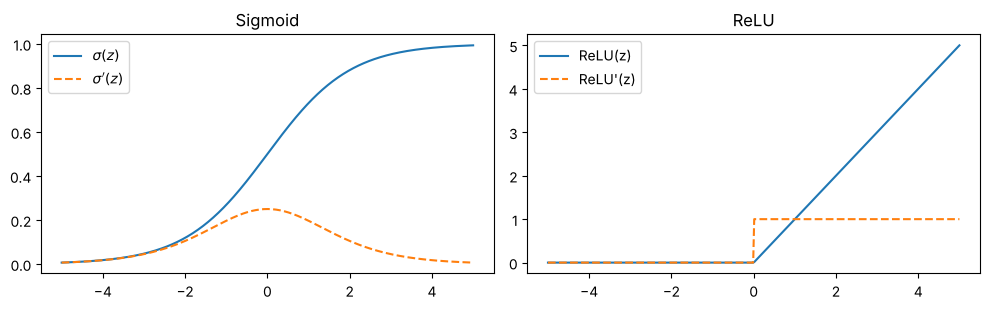

In [3]:
zz = np.linspace(-5, 5, 400)[None, :]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
s = nn.Sigmoid(); ax[0].plot(zz[0], s.forward(zz)[0], label=r"$\sigma(z)$")
ax[0].plot(zz[0], s.backward(np.ones_like(zz))[0], "--", label=r"$\sigma'(z)$"); ax[0].legend(); ax[0].set_title("Sigmoid")
r = nn.ReLU(); ax[1].plot(zz[0], r.forward(zz)[0], label="ReLU(z)")
ax[1].plot(zz[0], r.backward(np.ones_like(zz))[0], "--", label="ReLU'(z)"); ax[1].legend(); ax[1].set_title("ReLU")
plt.tight_layout(); plt.show()

## 2. Loss functions

Let $\hat y$ be the network output and $y$ the target, for $N$ samples.

### 2.1 Mean squared error (MSE) — regression
$$L_{\text{MSE}} = \frac{1}{N}\sum_{n=1}^{N}\sum_{k}\left(\hat y_{nk}-y_{nk}\right)^2$$

### 2.2 Binary cross-entropy (logistic-regression cost) — two classes, $\hat y=\sigma(z)\in(0,1)$
$$L_{\text{BCE}} = -\frac{1}{N}\sum_{n=1}^{N}\Big[y_n\log\hat y_n + (1-y_n)\log(1-\hat y_n)\Big]$$
It is the negative log-likelihood of a Bernoulli model $P(y=1\mid x)=\hat y$:
$P(y\mid x)=\hat y^{\,y}(1-\hat y)^{1-y}$, so $-\log P = -[y\log\hat y+(1-y)\log(1-\hat y)]$.

### 2.3 Softmax cross-entropy — $K$ classes, $y$ one-hot, $p=\mathrm{softmax}(z)$
$$L_{\text{CE}} = -\frac{1}{N}\sum_{n=1}^{N}\sum_{k=1}^{K} y_{nk}\log p_{nk} = -\frac{1}{N}\sum_{n}\log p_{n,c_n}$$
where $c_n$ is the true class of sample $n$ (negative log-likelihood of a categorical distribution).

### 2.4 Worked example (by hand)

**MSE and BCE** with $\hat y = (0.8,\;0.2,\;0.6)$, $y=(1,\;0,\;1)$, $N=3$:

$$L_{\text{MSE}}=\tfrac13\left[(0.8-1)^2+(0.2-0)^2+(0.6-1)^2\right]=\tfrac13\,[0.04+0.04+0.16]=\tfrac{0.24}{3}=\mathbf{0.08}$$

$$L_{\text{BCE}}=-\tfrac13\left[\log 0.8+\log(1-0.2)+\log 0.6\right]=-\tfrac13\,[-0.22314-0.22314-0.51083]=\tfrac{0.95711}{3}=\mathbf{0.31904}$$

**Softmax CE** with logits $z=(2,\;1,\;0.1)$ and true class 1 ($y=(1,0,0)$):

$$e^{z}=(7.38906,\;2.71828,\;1.10517),\quad \sum e^{z}=11.21251$$
$$p=(0.65900,\;0.24243,\;0.09857),\qquad L_{\text{CE}}=-\log 0.65900=\mathbf{0.41703}$$

In [4]:
yhat = np.array([[0.8], [0.2], [0.6]]); y = np.array([[1.0], [0.0], [1.0]])
print("MSE =", nn.MSE()(yhat, y))
print("BCE =", nn.BinaryCrossEntropy()(yhat, y))

z = np.array([[2.0, 1.0, 0.1]]); y_oh = np.array([[1.0, 0.0, 0.0]])
p = nn.Softmax().forward(z)
print("softmax p =", p, "  CE =", nn.SoftmaxCrossEntropy()(p, y_oh))

MSE = 0.08
BCE = 0.3190375754648034
softmax p = [[0.659001 0.242433 0.098566]]   CE = 0.4170300162778335


**Why cross-entropy instead of MSE for classification?** Below, the loss for a single positive sample ($y=1$)
is plotted as a function of the prediction. When the network is confidently wrong ($\hat y\to0$), BCE goes to
$\infty$ and produces a large gradient, whereas MSE is bounded by 1 and (combined with the sigmoid) its gradient
vanishes — see §3.2.

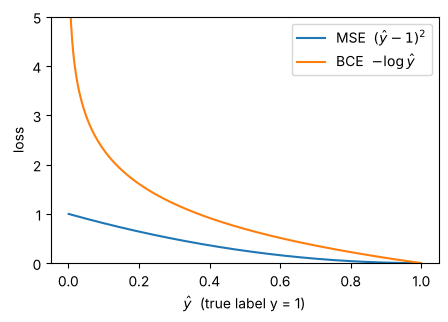

In [5]:
yh = np.linspace(0.001, 0.999, 300)
plt.figure(figsize=(5, 3.2))
plt.plot(yh, (yh - 1) ** 2, label="MSE  $(\\hat y-1)^2$")
plt.plot(yh, -np.log(yh), label="BCE  $-\\log\\hat y$")
plt.xlabel("$\\hat y$  (true label y = 1)"); plt.ylabel("loss"); plt.ylim(0, 5); plt.legend(); plt.show()

## 3. Deriving the gradient of the loss

We need $\partial L/\partial \hat y$ (gradient w.r.t. the output) and, more usefully, the gradient w.r.t. the
**pre-activation** of the last layer, $\delta^{[L]} = \partial L/\partial Z^{[L]}$, which is the starting point of backprop.

### 3.1 MSE
$$\frac{\partial L_{\text{MSE}}}{\partial \hat y_{nk}} = \frac{1}{N}\cdot 2(\hat y_{nk}-y_{nk}) = \frac{2}{N}(\hat y_{nk}-y_{nk})$$
With a **linear** output ($\hat y=z$): $\delta^{[L]} = \frac{2}{N}(\hat Y - Y)$.
With a **sigmoid** output ($\hat y=\sigma(z)$):
$$\delta^{[L]} = \frac{2}{N}(\hat y-y)\,\hat y(1-\hat y).$$

### 3.2 Binary cross-entropy
$$\frac{\partial L_{\text{BCE}}}{\partial \hat y_n} = -\frac{1}{N}\left[\frac{y_n}{\hat y_n}-\frac{1-y_n}{1-\hat y_n}\right]
= \frac{1}{N}\,\frac{\hat y_n-y_n}{\hat y_n(1-\hat y_n)}$$
With a sigmoid output, the chain rule multiplies by $\sigma'(z_n)=\hat y_n(1-\hat y_n)$, which **cancels the denominator**:
$$\boxed{\;\delta^{[L]}_n=\frac{\partial L_{\text{BCE}}}{\partial z_n} = \frac{1}{N}\,\frac{\hat y_n-y_n}{\hat y_n(1-\hat y_n)}\cdot\hat y_n(1-\hat y_n)=\frac{1}{N}(\hat y_n-y_n)\;}$$
Compare with MSE + sigmoid: $\frac{2}{N}(\hat y-y)\hat y(1-\hat y)$. When the output saturates (e.g. $\hat y\approx 0$ while
$y=1$) the factor $\hat y(1-\hat y)\approx0$ kills the MSE gradient, whereas the BCE gradient stays $\approx -1/N$.

### 3.3 Softmax cross-entropy
$$\frac{\partial L_{\text{CE}}}{\partial p_{nk}} = -\frac{1}{N}\frac{y_{nk}}{p_{nk}}$$
Chain rule through the softmax Jacobian $\partial p_k/\partial z_j=p_k(\delta_{kj}-p_j)$:
$$\frac{\partial L_{\text{CE}}}{\partial z_{nj}} = \sum_k \frac{\partial L}{\partial p_{nk}}\frac{\partial p_{nk}}{\partial z_{nj}}
= -\frac{1}{N}\sum_k \frac{y_{nk}}{p_{nk}}\,p_{nk}(\delta_{kj}-p_{nj})
= -\frac{1}{N}\Big(y_{nj} - p_{nj}\underbrace{\textstyle\sum_k y_{nk}}_{=1}\Big)$$
$$\boxed{\;\delta^{[L]} = \frac{\partial L_{\text{CE}}}{\partial Z} = \frac{1}{N}(P - Y)\;}$$

### 3.4 Gradient of the worked examples (by hand)

MSE: $\frac{2}{3}(\hat y-y)=\frac23(-0.2,\;0.2,\;-0.4)=(-0.13333,\;0.13333,\;-0.26667)$

BCE w.r.t. $\hat y$: $\frac13\frac{\hat y-y}{\hat y(1-\hat y)}=\frac13\left(\frac{-0.2}{0.16},\frac{0.2}{0.16},\frac{-0.4}{0.24}\right)=(-0.41667,\;0.41667,\;-0.55556)$

Softmax CE w.r.t. $z$: $p-y=(0.65900-1,\;0.24243,\;0.09857)=(-0.34100,\;0.24243,\;0.09857)$

### 3.5 Verification against finite differences

In [6]:
def fd(f, x, h=1e-6):
    return nn.numerical_gradient(f, x, h)

mse, bce, ce = nn.MSE(), nn.BinaryCrossEntropy(), nn.SoftmaxCrossEntropy()
print("dMSE/dyhat  analytic:", mse.grad(yhat, y).ravel(), " numeric:", fd(lambda: mse(yhat, y), yhat).ravel())
print("dBCE/dyhat  analytic:", bce.grad(yhat, y).ravel(), " numeric:", fd(lambda: bce(yhat, y), yhat).ravel())

# BCE through sigmoid -> (yhat - y)/N
zb = np.array([[1.3863], [-1.3863], [0.4055]])   # sigmoid(zb) ~ (0.8, 0.2, 0.6)
s = nn.Sigmoid(); yh = s.forward(zb)
print("dBCE/dz chain rule  :", s.backward(bce.grad(yh, y)).ravel(), "  (yhat-y)/N:", ((yh - y) / 3).ravel())

# softmax CE through softmax -> (p - y)/N
sm = nn.Softmax(); p = sm.forward(z)
dz_chain = sm.backward(ce.grad(p, y_oh))
dz_num = fd(lambda: ce(nn.Softmax().forward(z), y_oh), z)
print("dCE/dz   chain rule :", dz_chain, "  p-y:", p - y_oh, "  numeric:", dz_num)

dMSE/dyhat  analytic: [-0.133333  0.133333 -0.266667]  numeric: [-0.133333  0.133333 -0.266667]
dBCE/dyhat  analytic: [-0.416667  0.416667 -0.555556]  numeric: [-0.416667  0.416667 -0.555556]
dBCE/dz chain rule  : [-0.066666  0.066666 -0.133331]   (yhat-y)/N: [-0.066666  0.066666 -0.133331]
dCE/dz   chain rule : [[-0.340999  0.242433  0.098566]]   p-y: [[-0.340999  0.242433  0.098566]]   numeric: [[-0.340999  0.242433  0.098566]]


## 4. Backpropagation and optimisation

### 4.1 Backpropagation equations

Backprop is the chain rule applied layer by layer from the output back to the input, re-using
the quantities stored during the forward pass. Define the error signal of layer $l$ as
$\delta^{[l]} = \partial L/\partial Z^{[l]}$.

1. **Output layer:** $\delta^{[L]} = \dfrac{\partial L}{\partial A^{[L]}}\odot f^{[L]\prime}(Z^{[L]})$ — or directly the simplified forms of §3
   ($\tfrac1N(\hat Y-Y)$ for sigmoid+BCE, $\tfrac1N(P-Y)$ for softmax+CE).
2. **Parameter gradients:** $\dfrac{\partial L}{\partial W^{[l]}} = A^{[l-1]\top}\delta^{[l]}$, $\quad \dfrac{\partial L}{\partial b^{[l]}} = \sum_n \delta^{[l]}_{n,:}$
3. **Propagate to the previous layer:** $\delta^{[l-1]} = \left(\delta^{[l]}W^{[l]\top}\right)\odot f^{[l-1]\prime}\!\left(Z^{[l-1]}\right)$

Derivation of step 3: $Z^{[l]}_{nj}=\sum_i A^{[l-1]}_{ni}W^{[l]}_{ij}+b_j$, so
$\frac{\partial L}{\partial A^{[l-1]}_{ni}}=\sum_j\delta^{[l]}_{nj}W^{[l]}_{ij}=(\delta^{[l]}W^{[l]\top})_{ni}$, and
$A^{[l-1]}=f(Z^{[l-1]})$ is element-wise, so we multiply element-wise by $f'$.

The cost of the backward pass is of the same order as the forward pass (two matrix products per layer).
`nnlib.MLP.backward` implements exactly these three steps.

### 4.2 Worked numerical example of one forward + backward pass (by hand)

Network 2–2–1, sigmoid hidden and output units, BCE loss, one XOR sample $x=(1,\,0)$, $y=1$:

$$W^{[1]}=\begin{pmatrix}0.5 & -0.4\\ 0.3 & 0.6\end{pmatrix},\quad b^{[1]}=(0.1,\;-0.1),\qquad
W^{[2]}=\begin{pmatrix}0.7\\ -0.2\end{pmatrix},\quad b^{[2]}=0.05$$

**Forward pass**

$z^{[1]} = xW^{[1]}+b^{[1]} = (1\cdot0.5+0\cdot0.3+0.1,\;\;1\cdot(-0.4)+0\cdot0.6-0.1) = (0.6,\;-0.5)$

$a^{[1]} = \sigma(z^{[1]}) = \left(\frac{1}{1+e^{-0.6}},\;\frac{1}{1+e^{0.5}}\right) = (0.645656,\;0.377541)$

$z^{[2]} = 0.7\cdot0.645656 + (-0.2)\cdot0.377541 + 0.05 = 0.451959-0.075508+0.05 = 0.426451$

$\hat y = a^{[2]} = \sigma(0.426451) = 0.605026$

$L = -\log(0.605026) = 0.502484$

**Backward pass**

$\delta^{[2]} = \hat y - y = 0.605026-1 = -0.394974$ (sigmoid + BCE, §3.2)

$\dfrac{\partial L}{\partial W^{[2]}} = a^{[1]\top}\delta^{[2]} = \begin{pmatrix}0.645656\cdot(-0.394974)\\0.377541\cdot(-0.394974)\end{pmatrix} = \begin{pmatrix}-0.255017\\-0.149119\end{pmatrix},\qquad \dfrac{\partial L}{\partial b^{[2]}}=-0.394974$

$\dfrac{\partial L}{\partial a^{[1]}} = \delta^{[2]}W^{[2]\top} = (-0.394974\cdot0.7,\;-0.394974\cdot(-0.2)) = (-0.276482,\;0.078995)$

$\sigma'(z^{[1]}) = a^{[1]}(1-a^{[1]}) = (0.645656\cdot0.354344,\;0.377541\cdot0.622459) = (0.228784,\;0.235004)$

$\delta^{[1]} = (-0.276482\cdot0.228784,\;\;0.078995\cdot0.235004) = (-0.063255,\;0.018564)$

$\dfrac{\partial L}{\partial W^{[1]}} = x^{\top}\delta^{[1]} = \begin{pmatrix}1\\0\end{pmatrix}(-0.063255,\;0.018564) = \begin{pmatrix}-0.063255 & 0.018564\\ 0 & 0\end{pmatrix},\qquad \dfrac{\partial L}{\partial b^{[1]}}=(-0.063255,\;0.018564)$

(The second row is zero because $x_2=0$: an input that is zero receives no weight update.)

**One gradient-descent step** with $\eta=0.5$, $\theta\leftarrow\theta-\eta\nabla_\theta L$:

$W^{[2]} = \begin{pmatrix}0.7+0.5\cdot0.255017\\-0.2+0.5\cdot0.149119\end{pmatrix}=\begin{pmatrix}0.827509\\-0.125441\end{pmatrix},\quad b^{[2]}=0.05+0.5\cdot0.394974=0.247487$

$W^{[1]} = \begin{pmatrix}0.531627 & -0.409282\\0.3 & 0.6\end{pmatrix},\quad b^{[1]} = (0.131627,\;-0.109282)$

After the update the prediction rises to $\hat y = 0.678486$ and the loss falls from $0.502484$ to $0.387892$.

The cell below reproduces every number with the library.

In [7]:
model = nn.MLP([2, 2, 1], ["sigmoid", "sigmoid"])
model.layers[0].W[:] = [[0.5, -0.4], [0.3, 0.6]]; model.layers[0].b[:] = [0.1, -0.1]
model.layers[1].W[:] = [[0.7], [-0.2]];           model.layers[1].b[:] = [0.05]
x = np.array([[1.0, 0.0]]); t = np.array([[1.0]]); bce = nn.BinaryCrossEntropy()

yhat = model.forward(x)
print("z1 =", model.layers[0].forward(x), " a1 =", model.acts[0].a, " yhat =", yhat, " loss =", bce(yhat, t))
model.forward(x); model.backward(bce.grad(yhat, t))
for i, l in enumerate(model.layers, 1):
    print(f"dW{i} =\n{l.dW}\ndb{i} = {l.db}")
nn.GD(lr=0.5).step(*model.params())
print("after one GD step: W1 =\n", model.layers[0].W, "\nb1 =", model.layers[0].b,
      "\nW2 =", model.layers[1].W.ravel(), " b2 =", model.layers[1].b)
print("new yhat =", model.forward(x), " new loss =", bce(model.forward(x), t))

z1 = [[ 0.6 -0.5]]  a1 = [[0.645656 0.377541]]  yhat = [[0.605026]]  loss = 0.5024839303100508
dW1 =
[[-0.063255  0.018564]
 [ 0.        0.      ]]
db1 = [-0.063255  0.018564]
dW2 =
[[-0.255017]
 [-0.149119]]
db2 = [-0.394974]
after one GD step: W1 =
 [[ 0.531627 -0.409282]
 [ 0.3       0.6     ]] 
b1 = [ 0.131627 -0.109282] 
W2 = [ 0.827509 -0.125441]  b2 = [0.247487]
new yhat = [[0.678486]]  new loss = 0.3878915114921341


### 4.3 Gradient check of backprop

For every parameter $\theta$ we compare the backprop gradient with the central difference
$\frac{L(\theta+h)-L(\theta-h)}{2h}$ and report the relative error
$\frac{\lVert g_{num}-g_{bp}\rVert}{\lVert g_{num}\rVert+\lVert g_{bp}\rVert}$. Values around $10^{-7}$ or smaller confirm a correct
implementation for every architecture / loss combination used in this assignment.

In [8]:
rng = np.random.default_rng(1)
Xc = rng.normal(size=(6, 3))
checks = {
    "sigmoid MLP + BCE":   (nn.MLP([3, 5, 1], ["sigmoid", "sigmoid"], seed=2), nn.BinaryCrossEntropy(), rng.integers(0, 2, (6, 1)).astype(float)),
    "sigmoid MLP + MSE":   (nn.MLP([3, 5, 1], ["sigmoid", "sigmoid"], seed=3), nn.MSE(), rng.uniform(size=(6, 1))),
    "ReLU MLP + MSE":      (nn.MLP([3, 5, 4, 2], ["relu", "relu", "linear"], seed=4), nn.MSE(), rng.normal(size=(6, 2))),
    "ReLU MLP + softmax CE": (nn.MLP([3, 6, 6, 4], ["relu", "relu", "softmax"], seed=5), nn.SoftmaxCrossEntropy(), nn.one_hot(rng.integers(0, 4, 6), 4)),
}
for name, (m, loss, Yc) in checks.items():
    print(f"{name:24s} max relative error = {nn.gradient_check(m, loss, Xc, Yc):.2e}")

sigmoid MLP + BCE        max relative error = 5.06e-09
sigmoid MLP + MSE        max relative error = 5.15e-09
ReLU MLP + MSE           max relative error = 6.74e-10
ReLU MLP + softmax CE    max relative error = 2.08e-09


### 4.4 Gradient Descent (batch GD)
Uses the gradient of the loss over the **entire** training set at every step:
$$\theta_{t+1} = \theta_t - \eta\,\nabla_\theta L(\theta_t),\qquad \nabla_\theta L = \frac{1}{N}\sum_{n=1}^{N}\nabla_\theta \ell_n(\theta).$$
Exact gradient, smooth monotone decrease for small $\eta$, but each step costs a pass over all $N$ samples.

For a quadratic $L(w)=\tfrac{\lambda}{2}w^2$, $w_{t+1}=(1-\eta\lambda)w_t$, so GD converges iff $|1-\eta\lambda|<1\iff 0<\eta<2/\lambda$.

### 4.5 Stochastic Gradient Descent (SGD)
Uses an unbiased estimate of the gradient from one sample (or a mini-batch $\mathcal B$ of size $B$):
$$\theta_{t+1} = \theta_t - \eta\,\frac{1}{B}\sum_{n\in\mathcal B}\nabla_\theta \ell_n(\theta_t),\qquad
\mathbb E_{\mathcal B}\!\left[\tfrac1B\textstyle\sum_{n\in\mathcal B}\nabla\ell_n\right]=\nabla L.$$
Many cheap, noisy updates per epoch; the noise can help escape poor regions, but the loss curve fluctuates.

### 4.6 SGD with Momentum
Accumulates an exponentially decaying average of past gradients (a "velocity"):
$$v_{t+1} = \beta v_t + \nabla_\theta L(\theta_t),\qquad \theta_{t+1} = \theta_t - \eta\, v_{t+1},\qquad v_0=0.$$
Unrolling, $v_{t+1}=\sum_{k=0}^{t}\beta^{k}\nabla L(\theta_{t-k})$; for a constant gradient $g$ the step approaches $\frac{\eta}{1-\beta}g$
(10× larger for $\beta=0.9$). Oscillating gradient components cancel while consistent ones add up, which accelerates
progress along shallow valleys and damps zig-zagging.

### 4.7 Worked examples (by hand)

**GD vs. Momentum** on $L(w)=w^2$ ($\nabla L=2w$), $w_0=1$, $\eta=0.1$, $\beta=0.9$:

| step | GD: $w_{t+1}=w_t-0.1\cdot2w_t$ | Momentum: $v_{t+1}=0.9v_t+2w_t$ | Momentum: $w_{t+1}=w_t-0.1v_{t+1}$ |
|---|---|---|---|
| 1 | $1-0.2=0.8$ | $0+2=2$ | $1-0.2=0.8$ |
| 2 | $0.8-0.16=0.64$ | $1.8+1.6=3.4$ | $0.8-0.34=0.46$ |
| 3 | $0.64-0.128=0.512$ | $3.06+0.92=3.98$ | $0.46-0.398=0.062$ |

Momentum reaches $0.062$ after three steps, GD only $0.512$.

**GD vs. SGD** for linear regression $\hat y=wx$ with data $(x,y)\in\{(1,2),(2,4)\}$ (true $w^\*=2$), $\ell_n=(wx_n-y_n)^2$, $\eta=0.1$, $w_0=0$:

* GD: $\nabla L=\frac12\sum_n 2x_n(wx_n-y_n)$.
  Step 1: $\nabla L = 1(0-2)+2(0-4)=-10\Rightarrow w_1=0+0.1\cdot10=1.0$.
  Step 2: $\nabla L = 1(1-2)+2(2-4)=-5\Rightarrow w_2=1.5$. Step 3: $\nabla L=-2.5\Rightarrow w_3=1.75$.
* SGD (one sample per update, order $(1,2)$ then $(2,4)$), $\nabla\ell_n = 2x_n(wx_n-y_n)$:
  $w=0\xrightarrow{\;2\cdot1(0-2)=-4\;}0.4\xrightarrow{\;2\cdot2(0.8-4)=-12.8\;}1.68$ (end of epoch 1),
  $\xrightarrow{\;2(1.68-2)=-0.64\;}1.744\xrightarrow{\;4(3.488-4)=-2.048\;}1.9488$ (end of epoch 2).

After 2 epochs SGD is at $1.9488$ (4 updates) while GD is at $1.5$ (2 updates).

In [9]:
# reproduce the hand calculations
w = np.array([1.0]); gd = nn.GD(0.1); traj = []
for _ in range(3): gd.step([w], [2 * w]); traj.append(w[0])
print("GD       on w^2:", np.round(traj, 6))
w = np.array([1.0]); mom = nn.Momentum(0.1, 0.9); traj = []
for _ in range(3): mom.step([w], [2 * w]); traj.append(w[0])
print("Momentum on w^2:", np.round(traj, 6))

Xr, Yr = np.array([1.0, 2.0]), np.array([2.0, 4.0])
w = np.array([0.0]); traj = []
for _ in range(3): nn.GD(0.1).step([w], [np.mean(2 * Xr * (w * Xr - Yr))]); traj.append(w[0])
print("GD  linear regression:", np.round(traj, 6))
w = np.array([0.0]); traj = []
for _ in range(2):
    for xn, yn in zip(Xr, Yr):
        nn.SGD(0.1).step([w], [2 * xn * (w * xn - yn)]); traj.append(w[0])
print("SGD linear regression:", np.round(traj, 6))

GD       on w^2: [0.8   0.64  0.512]
Momentum on w^2: [0.8   0.46  0.062]
GD  linear regression: [1.   1.5  1.75]
SGD linear regression: [0.4    1.68   1.744  1.9488]


**Optimiser trajectories on an ill-conditioned quadratic** $L(w)=\tfrac12(w_1^2+25w_2^2)$, $\eta=0.07$:
GD zig-zags along the steep $w_2$ direction and creeps along the shallow $w_1$ direction (it cannot use a larger
step: GD diverges for $\eta>2/25=0.08$). SGD (simulated by adding Gaussian noise to the gradient) follows GD on average but jitters.
Momentum with a well-chosen $\beta$ ($\eta=0.04,\beta=0.7$) builds up speed along $w_1$ while the oscillations in $w_2$ cancel,
reaching a loss several orders of magnitude lower in 60 steps. With too much momentum ($\beta=0.9$) the iterate overshoots
and oscillates around the minimum — $\beta$ and $\eta$ have to be tuned together.

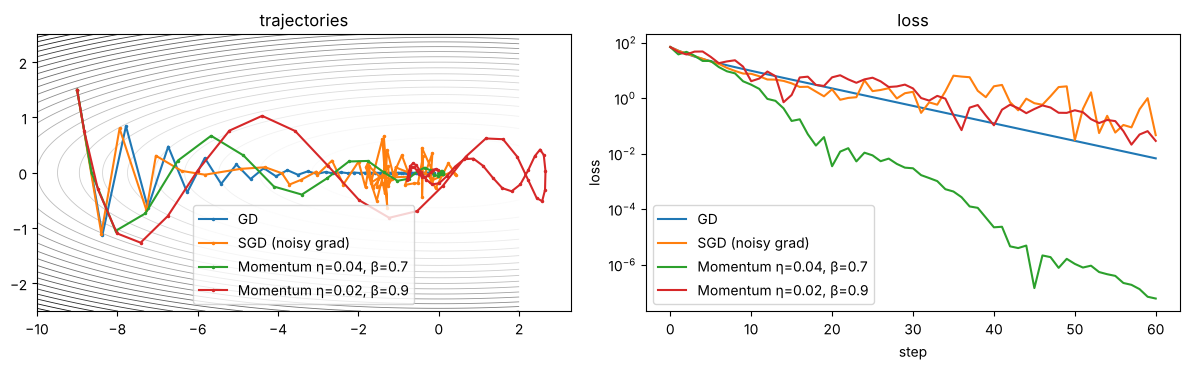

In [10]:
H = np.array([1.0, 25.0]); grad_q = lambda w: H * w
def run(opt, noise=0.0, steps=60, seed=0):
    rng = np.random.default_rng(seed); w = np.array([-9.0, 1.5]); path = [w.copy()]
    for _ in range(steps):
        opt.step([w], [grad_q(w) + noise * rng.normal(size=2)]); path.append(w.copy())
    return np.array(path)
paths = {"GD": run(nn.GD(0.07)), "SGD (noisy grad)": run(nn.SGD(0.07), noise=3.0), "Momentum η=0.04, β=0.7": run(nn.Momentum(0.04, 0.7)), "Momentum η=0.02, β=0.9": run(nn.Momentum(0.02, 0.9))}
g1, g2 = np.meshgrid(np.linspace(-10, 2, 200), np.linspace(-2.5, 2.5, 200))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].contour(g1, g2, 0.5 * (g1 ** 2 + 25 * g2 ** 2), levels=25, cmap="Greys", linewidths=0.6)
for k, pth in paths.items():
    ax[0].plot(pth[:, 0], pth[:, 1], ".-", ms=3, label=k)
    ax[1].semilogy(0.5 * (pth[:, 0] ** 2 + 25 * pth[:, 1] ** 2), label=k)
ax[0].legend(); ax[0].set_title("trajectories"); ax[1].set_xlabel("step"); ax[1].set_ylabel("loss"); ax[1].legend(); ax[1].set_title("loss")
plt.tight_layout(); plt.show()

## 5. Models

### 5.1 Fully-connected neural network with sigmoid activation

Architecture $2\to16\to16\to1$, sigmoid in **every** layer, BCE loss, trained on the (non-linearly separable)
two-moons data set:

$$\hat y = \sigma\!\Big(\sigma\big(\sigma(XW^{[1]}+b^{[1]})W^{[2]}+b^{[2]}\big)W^{[3]}+b^{[3]}\Big)$$

Backprop: $\delta^{[3]}=\frac1N(\hat Y-Y)$, then $\delta^{[l]}=(\delta^{[l+1]}W^{[l+1]\top})\odot A^{[l]}\odot(1-A^{[l]})$ for $l=2,1$.
We compare the three optimisers on the same network and initialisation.

GD (full batch, lr=1.0)              final loss 0.2512   accuracy 0.882


SGD (batch 16, lr=1.0)               final loss 0.0103   accuracy 0.993


Momentum (batch 16, lr=0.1, β=0.9)   final loss 0.0081   accuracy 0.998


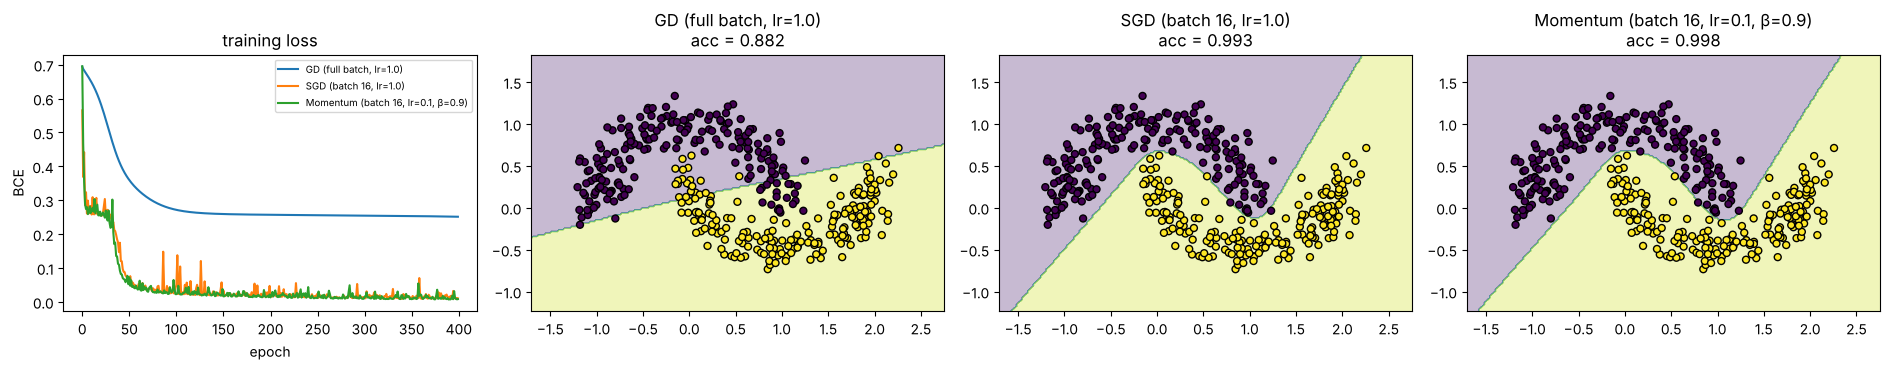

In [11]:
X, lab = nn.make_moons(400, noise=0.15, seed=0)
Y = lab[:, None].astype(float)
configs = {
    "GD (full batch, lr=1.0)":       (nn.GD(1.0), None),
    "SGD (batch 16, lr=1.0)":        (nn.SGD(1.0), 16),
    "Momentum (batch 16, lr=0.1, β=0.9)": (nn.Momentum(0.1, 0.9), 16),
}
fig, ax = plt.subplots(1, 4, figsize=(19, 3.8)); models_sig = {}
for i, (name, (opt, bs)) in enumerate(configs.items()):
    m = nn.MLP([2, 16, 16, 1], ["sigmoid", "sigmoid", "sigmoid"], seed=0)
    hist = nn.train(m, nn.BinaryCrossEntropy(), opt, X, Y, epochs=400, batch_size=bs)
    models_sig[name] = m
    ax[0].plot(hist, label=name)
    plot_boundary(m, X, lab, ax[i + 1], f"{name}\nacc = {nn.accuracy(m, X, lab):.3f}")
    print(f"{name:36s} final loss {hist[-1]:.4f}   accuracy {nn.accuracy(m, X, lab):.3f}")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("BCE"); ax[0].legend(fontsize=7); ax[0].set_title("training loss")
plt.tight_layout(); plt.show()

With the same number of epochs, full-batch GD makes only 400 updates and is still on a plateau (sigmoid
networks learn slowly — $\sigma'\le0.25$ shrinks the gradient in every layer), SGD makes 25 updates per epoch and
learns the curved boundary, and momentum converges fastest and most smoothly.

### 5.2 Two-layer ReLU network for the XOR problem

XOR is **not linearly separable**: a single linear unit $\hat y = w_1x_1+w_2x_2+b$ thresholded at $0.5$ would need
$b<0.5$ (for $(0,0)\mapsto0$), $w_1+b>0.5$ and $w_2+b>0.5$, hence $w_1+w_2+2b>1$, i.e. $w_1+w_2+b>1-b>0.5$, contradicting
$(1,1)\mapsto0$. A hidden layer with a non-linearity fixes this.

**Exact analytical solution** (Goodfellow et al., *Deep Learning*, §6.1) — $f(x)=w^{\top}\mathrm{ReLU}(W^{\top}x+c)+b$ with

$$W=\begin{pmatrix}1&1\\1&1\end{pmatrix},\quad c=\begin{pmatrix}0\\-1\end{pmatrix},\quad w=\begin{pmatrix}1\\-2\end{pmatrix},\quad b=0.$$

| $x$ | $z=xW+c$ | $h=\mathrm{ReLU}(z)$ | $\hat y = h\,w$ | XOR |
|---|---|---|---|---|
| $(0,0)$ | $(0,\;-1)$ | $(0,\;0)$ | $0$ | 0 |
| $(0,1)$ | $(1,\;0)$ | $(1,\;0)$ | $1$ | 1 |
| $(1,0)$ | $(1,\;0)$ | $(1,\;0)$ | $1$ | 1 |
| $(1,1)$ | $(2,\;1)$ | $(2,\;1)$ | $2-2=0$ | 0 |

In hidden space $(h_1,h_2)$ the four points become $(0,0)$, $(1,0)$, $(1,0)$, $(2,1)$ — the two positive inputs collapse onto the
same point and the classes **are** linearly separable (e.g. by $h_1-2h_2=0.5$).

In [12]:
Xx, Yx = nn.xor_data()
relu_xor = nn.MLP([2, 2, 1], ["relu", "linear"])
relu_xor.layers[0].W[:] = [[1, 1], [1, 1]]; relu_xor.layers[0].b[:] = [0, -1]
relu_xor.layers[1].W[:] = [[1], [-2]];     relu_xor.layers[1].b[:] = [0]
print("hidden h =\n", nn.ReLU().forward(Xx @ relu_xor.layers[0].W + relu_xor.layers[0].b) + 0.0)
print("output   =", relu_xor.forward(Xx).ravel(), " target =", Yx.ravel(), " MSE =", nn.MSE()(relu_xor.forward(Xx), Yx))

hidden h =
 [[0. 0.]
 [1. 0.]
 [1. 0.]
 [2. 1.]]
output   = [0. 1. 1. 0.]  target = [0. 1. 1. 0.]  MSE = 0.0


**Learning the ReLU XOR network with gradient descent** (MSE loss, linear output, $2\to H\to1$).
Gradients: $\delta^{[2]}=\frac2N(\hat Y-Y)$, $\;\partial L/\partial W^{[2]}=H^{\top}\delta^{[2]}$, $\;\delta^{[1]}=(\delta^{[2]}W^{[2]\top})\odot\mathbb 1[Z^{[1]}>0]$,
$\;\partial L/\partial W^{[1]}=X^{\top}\delta^{[1]}$.

With only 2 hidden ReLUs, training from a random start can get stuck when a unit becomes "dead" ($z<0$ for all four
inputs ⇒ zero gradient forever). We therefore measure the success rate over 50 random initialisations for 2 and for 4 hidden units.

In [13]:
def xor_success(hidden, seeds=50, epochs=2000):
    ok, best = 0, None
    for s in range(seeds):
        m = nn.MLP([2, hidden, 1], ["relu", "linear"], seed=s)
        h = nn.train(m, nn.MSE(), nn.Momentum(0.05, 0.9), Xx, Yx, epochs=epochs)
        solved = np.all((m.forward(Xx) > 0.5) == (Yx > 0.5))
        ok += solved
        if solved and best is None: best = (m, h)
    return ok / seeds, best
solved_runs = {}
for H_ in (2, 4):
    rate, (m, h) = xor_success(H_)
    solved_runs[H_] = (m, h)
    print(f"{H_} hidden ReLUs: solved XOR in {rate:.0%} of runs; example output {m.forward(Xx).ravel().round(4)}  final MSE {h[-1]:.2e}")

2 hidden ReLUs: solved XOR in 20% of runs; example output [0. 1. 1. 0.]  final MSE 7.39e-94


4 hidden ReLUs: solved XOR in 64% of runs; example output [ 0.  1.  1. -0.]  final MSE 2.17e-34


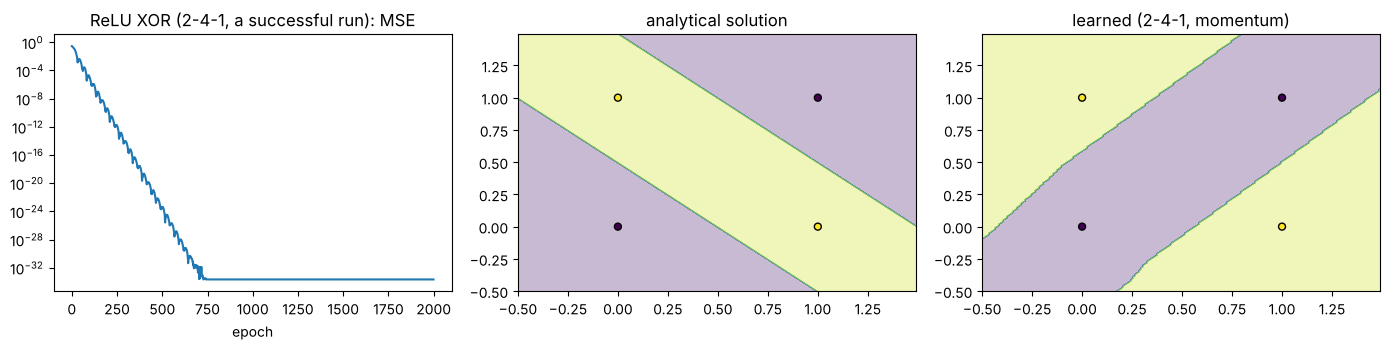

In [14]:
m, h = solved_runs[4]   # first initialisation (2-4-1) that solved XOR
class Thresh:  # wrap for decision-boundary plot
    def __init__(s, m): s.m = m
    def predict(s, X): return (s.m.forward(X)[:, 0] > 0.5).astype(int)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].semilogy(h); ax[0].set_title("ReLU XOR (2-4-1, a successful run): MSE"); ax[0].set_xlabel("epoch")
plot_boundary(Thresh(relu_xor), Xx, Yx.ravel(), ax[1], "analytical solution", h=0.01)
plot_boundary(Thresh(m), Xx, Yx.ravel(), ax[2], "learned (2-4-1, momentum)", h=0.01)
plt.tight_layout(); plt.show()

### 5.3 Gradient-based learning for XOR with the sigmoid function

Network $2\to2\to1$ with sigmoid hidden and output units, trained with BCE by full-batch gradient descent
on the four XOR points. The update rule for every parameter is exactly the backprop equations of §4.1
(the first iteration of this procedure on one sample was computed by hand in §4.2):

$$\delta^{[2]}=\tfrac14(\hat y-y),\quad
\nabla_{W^{[2]}}=A^{[1]\top}\delta^{[2]},\quad
\delta^{[1]}=(\delta^{[2]}W^{[2]\top})\odot A^{[1]}\odot(1-A^{[1]}),\quad
\nabla_{W^{[1]}}=X^{\top}\delta^{[1]},$$
$$W\leftarrow W-\eta\nabla_W,\qquad b\leftarrow b-\eta\nabla_b.$$

Below the loop is written **explicitly** (no library training loop) so every step of gradient-based learning is visible.

In [15]:
rng = np.random.default_rng(3)
W1, b1 = rng.normal(0, 1, (2, 2)), np.zeros(2)
W2, b2 = rng.normal(0, 1, (2, 1)), np.zeros(1)
sigmoid = lambda z: 1 / (1 + np.exp(-z))
eta, losses = 2.0, []
for epoch in range(5000):
    # forward
    A1 = sigmoid(Xx @ W1 + b1)
    A2 = sigmoid(A1 @ W2 + b2)
    losses.append(-np.mean(Yx * np.log(A2) + (1 - Yx) * np.log(1 - A2)))
    # backward
    d2 = (A2 - Yx) / len(Xx)
    dW2, db2 = A1.T @ d2, d2.sum(0)
    d1 = (d2 @ W2.T) * A1 * (1 - A1)
    dW1, db1 = Xx.T @ d1, d1.sum(0)
    # gradient-descent update
    W1 -= eta * dW1; b1 -= eta * db1; W2 -= eta * dW2; b2 -= eta * db2
    if epoch in (0, 1, 10, 100, 1000, 4999):
        print(f"epoch {epoch:4d}  BCE {losses[-1]:.5f}  outputs {A2.ravel().round(4)}")
print("\nlearned W1 =\n", W1, "\nb1 =", b1, "\nW2 =", W2.ravel(), " b2 =", b2)
print("hidden representation of the 4 inputs:\n", sigmoid(Xx @ W1 + b1).round(3))

epoch    0  BCE 0.71231  outputs [0.4172 0.4132 0.3974 0.3951]
epoch    1  BCE 0.69336  outputs [0.4855 0.4854 0.4784 0.4773]
epoch   10  BCE 0.68692  outputs [0.4794 0.4953 0.5114 0.514 ]
epoch  100  BCE 0.49349  outputs [0.1291 0.6981 0.5492 0.584 ]
epoch 1000  BCE 0.00601  outputs [0.005  0.9934 0.9935 0.0058]
epoch 4999  BCE 0.00098  outputs [0.0008 0.9989 0.9989 0.0009]

learned W1 =
 [[ 6.290942 -7.899761]
 [ 6.282801 -7.844955]] 
b1 = [-9.706535  3.329019] 
W2 = [-15.307717 -15.069808]  b2 = [7.478384]
hidden representation of the 4 inputs:
 [[0.    0.965]
 [0.032 0.011]
 [0.032 0.01 ]
 [0.946 0.   ]]


The hidden representation shows what was learned: hidden unit 1 is active only for $(1,1)$ (an **AND** detector) and
hidden unit 2 only for $(0,0)$ (a **NOR** detector). Both output weights are large and negative with a positive bias, so the
output fires exactly when *neither* detector fires: $\mathrm{XOR}=\neg(\mathrm{AND}\lor\mathrm{NOR})$. The hidden layer has made the
problem linearly separable.

**MSE vs. BCE and the effect of the optimiser on sigmoid-XOR.** Over 30 random initialisations we compare the loss
functions (with GD) and the optimisers (with BCE). The minimal 2-2-1 sigmoid network has local minima/plateaus, so
no setting solves XOR from every initialisation (success rates are similar). The difference shows in *how far* training
gets: because BCE removes the $\hat y(1-\hat y)$ factor from the output gradient (§3.2), the runs trained with BCE reach a
roughly 10× lower final loss than MSE in the same number of epochs.

In [16]:
def sig_xor(loss, opt_fn, seeds=30, epochs=3000, bs=None):
    hs, ok = [], 0
    for s in range(seeds):
        m = nn.MLP([2, 2, 1], ["sigmoid", "sigmoid"], seed=s, init="xavier")
        for l in m.layers: l.W *= 2   # larger init: helps sigmoid nets leave the symmetric plateau
        h = nn.train(m, loss, opt_fn(), Xx, Yx, epochs=epochs, batch_size=bs, seed=s)
        ok += np.all(m.predict(Xx) == Yx.ravel()); hs.append(nn.BinaryCrossEntropy()(m.forward(Xx), Yx))
    return ok / seeds, np.median(hs)
for name, loss, opt, bs in [("BCE + GD (lr=2)", nn.BinaryCrossEntropy(), lambda: nn.GD(2.0), None),
                            ("MSE + GD (lr=2)", nn.MSE(), lambda: nn.GD(2.0), None),
                            ("BCE + SGD (batch 1, lr=0.5)", nn.BinaryCrossEntropy(), lambda: nn.SGD(0.5), 1),
                            ("BCE + Momentum (lr=0.2, β=0.9)", nn.BinaryCrossEntropy(), lambda: nn.Momentum(0.2, 0.9), None)]:
    rate, med = sig_xor(loss, opt, bs=bs)
    print(f"{name:32s} solved {rate:5.0%} of runs, median final BCE {med:.4f}")

BCE + GD (lr=2)                  solved   73% of runs, median final BCE 0.0017


MSE + GD (lr=2)                  solved   80% of runs, median final BCE 0.0232


BCE + SGD (batch 1, lr=0.5)      solved   67% of runs, median final BCE 0.0018


BCE + Momentum (lr=0.2, β=0.9)   solved   77% of runs, median final BCE 0.0017


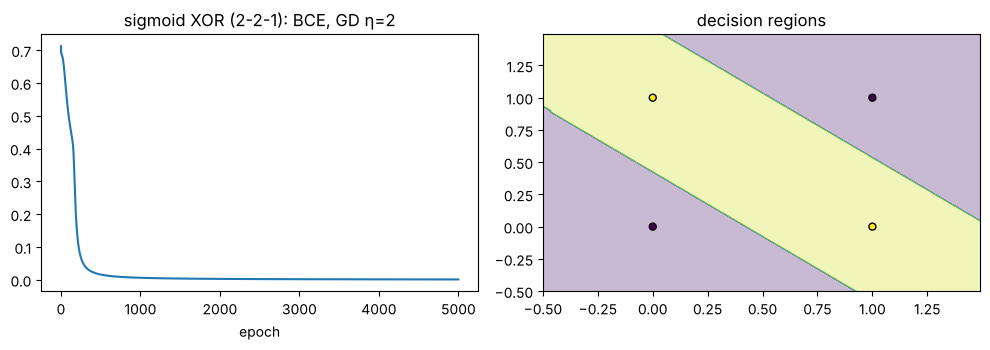

In [17]:
class Prob:
    def __init__(s, W1, b1, W2, b2): s.p = (W1, b1, W2, b2)
    def predict(s, X):
        W1, b1, W2, b2 = s.p; return (sigmoid(sigmoid(X @ W1 + b1) @ W2 + b2)[:, 0] > 0.5).astype(int)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(losses); ax[0].set_title("sigmoid XOR (2-2-1): BCE, GD η=2"); ax[0].set_xlabel("epoch")
plot_boundary(Prob(W1, b1, W2, b2), Xx, Yx.ravel(), ax[1], "decision regions", h=0.01)
plt.tight_layout(); plt.show()

### 5.4 Fully-connected MLP for multi-class classification (softmax output)

Architecture $2\to64\to64\to3$ with ReLU hidden layers and a **softmax** output layer, softmax cross-entropy loss,
trained on a 3-class spiral data set (not separable by any linear or shallow model).

$$P = \mathrm{softmax}\!\left(\mathrm{ReLU}\big(\mathrm{ReLU}(XW^{[1]}+b^{[1]})W^{[2]}+b^{[2]}\big)W^{[3]}+b^{[3]}\right),\qquad
L=-\frac1N\sum_n\log P_{n,c_n}$$

Backprop starts from $\delta^{[3]}=\frac1N(P-Y)$ (§3.3), then $\delta^{[l]}=(\delta^{[l+1]}W^{[l+1]\top})\odot\mathbb 1[Z^{[l]}>0]$.
Prediction: $\hat c_n=\arg\max_k P_{nk}$. Data are split 80/20 into train/test.

GD (lr=1.0)                            train acc 1.000   test acc 1.000


SGD (batch 32, lr=0.2)                 train acc 1.000   test acc 1.000


Momentum (batch 32, lr=0.02, β=0.9)    train acc 1.000   test acc 1.000


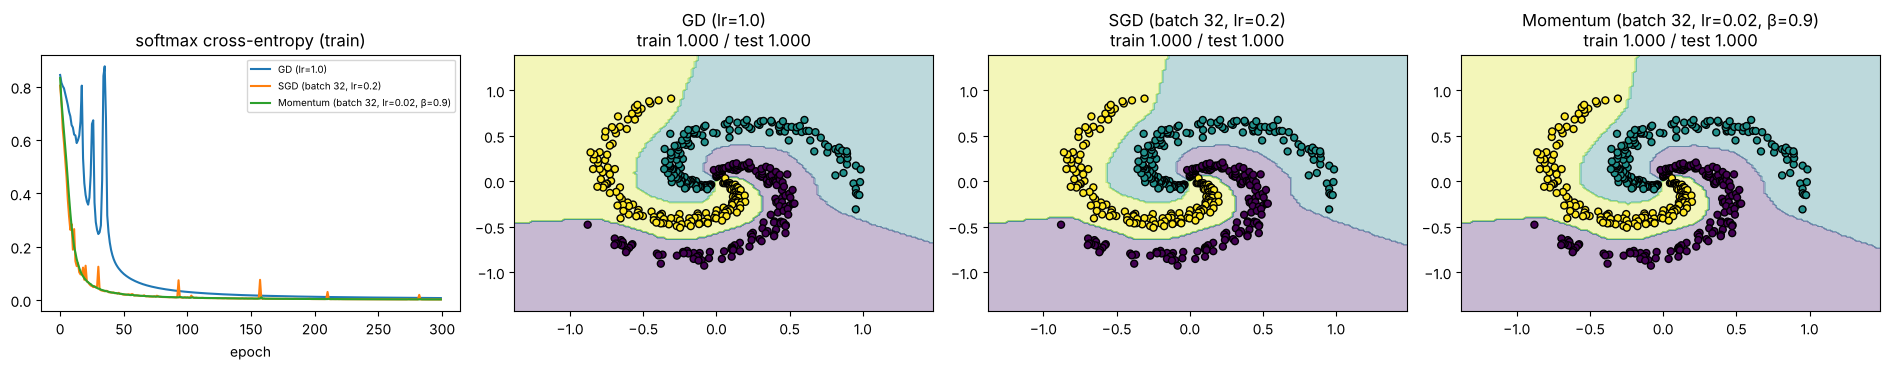

class probabilities of the first 3 test points:
 [[0.000029 0.999971 0.      ]
 [0.       0.000008 0.999992]
 [0.999862 0.       0.000138]] 
row sums: [1. 1. 1.]


In [18]:
Xs, ls = nn.make_spiral(150, 3, noise=0.2, seed=0)
perm = np.random.default_rng(0).permutation(len(Xs)); tr, te = perm[:360], perm[360:]
Ys = nn.one_hot(ls, 3)
fig, ax = plt.subplots(1, 4, figsize=(19, 3.8))
for i, (name, opt, bs) in enumerate([("GD (lr=1.0)", nn.GD(1.0), None),
                                     ("SGD (batch 32, lr=0.2)", nn.SGD(0.2), 32),
                                     ("Momentum (batch 32, lr=0.02, β=0.9)", nn.Momentum(0.02, 0.9), 32)]):
    m = nn.MLP([2, 64, 64, 3], ["relu", "relu", "softmax"], seed=0)
    h = nn.train(m, nn.SoftmaxCrossEntropy(), opt, Xs[tr], Ys[tr], epochs=300, batch_size=bs)
    ax[0].plot(h, label=name)
    plot_boundary(m, Xs, ls, ax[i + 1], f"{name}\ntrain {nn.accuracy(m, Xs[tr], ls[tr]):.3f} / test {nn.accuracy(m, Xs[te], ls[te]):.3f}")
    print(f"{name:38s} train acc {nn.accuracy(m, Xs[tr], ls[tr]):.3f}   test acc {nn.accuracy(m, Xs[te], ls[te]):.3f}")
ax[0].set_title("softmax cross-entropy (train)"); ax[0].set_xlabel("epoch"); ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()
print("class probabilities of the first 3 test points:\n", m.forward(Xs[te[:3]]), "\nrow sums:", m.forward(Xs[te[:3]]).sum(1))

### 5.5 Multi-layer Perceptron (MLP) — a general deep network

`nnlib.MLP(sizes, activations)` builds an MLP of **any** depth and width; the same forward/backward code is used for all
models in this notebook. As a final demonstration, a deeper MLP $1\to32\to32\to32\to1$ (ReLU hidden layers, linear output)
is trained as a **regressor with the MSE loss** to approximate $y=\sin(2\pi x)+0.5x$ from noisy samples, comparing the
three optimisers. (By the universal approximation theorem, an MLP with enough hidden units can approximate any continuous
function on a compact set.)

GD (lr=0.05)                           final MSE 0.0284


SGD (batch 16, lr=0.01)                final MSE 0.0112


Momentum (batch 16, lr=0.002, β=0.9)   final MSE 0.0098


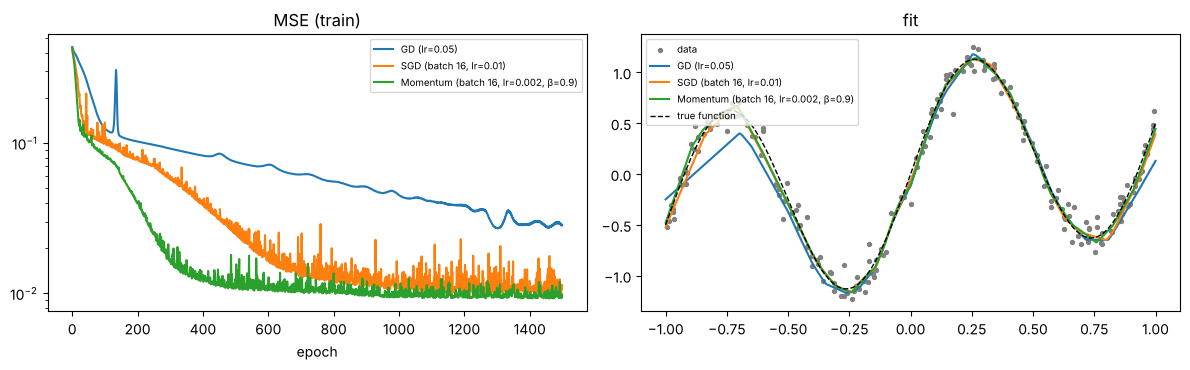

In [19]:
rng = np.random.default_rng(0)
xr = np.sort(rng.uniform(-1, 1, 200))[:, None]
yr = np.sin(2 * np.pi * xr) + 0.5 * xr + rng.normal(0, 0.1, xr.shape)
xg = np.linspace(-1, 1, 400)[:, None]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[1].scatter(xr, yr, s=8, c="grey", label="data")
for name, opt, bs in [("GD (lr=0.05)", nn.GD(0.05), None), ("SGD (batch 16, lr=0.01)", nn.SGD(0.01), 16),
                      ("Momentum (batch 16, lr=0.002, β=0.9)", nn.Momentum(0.002, 0.9), 16)]:
    m = nn.MLP([1, 32, 32, 32, 1], ["relu", "relu", "relu", "linear"], seed=1)
    h = nn.train(m, nn.MSE(), opt, xr, yr, epochs=1500, batch_size=bs)
    ax[0].semilogy(h, label=name); ax[1].plot(xg, m.forward(xg), label=name)
    print(f"{name:38s} final MSE {h[-1]:.4f}")
ax[1].plot(xg, np.sin(2 * np.pi * xg) + 0.5 * xg, "k--", lw=1, label="true function")
ax[0].set_title("MSE (train)"); ax[0].set_xlabel("epoch"); ax[0].legend(fontsize=7); ax[1].legend(fontsize=7); ax[1].set_title("fit")
plt.tight_layout(); plt.show()

## 6. Summary

* **Models.** A single generic MLP implementation (dense layers + sigmoid / ReLU / linear / softmax activations) covers the
  sigmoid FC network (§5.1), the ReLU XOR network with its exact analytical solution (§5.2), gradient-based learning of
  XOR with sigmoids (§5.3), softmax multi-class classification (§5.4) and deep MLP regression (§5.5).
* **Losses.** MSE, BCE and softmax CE are implemented with their gradients and evaluated by hand (§2.4, §3.4).
* **Gradients.** Sigmoid + BCE gives $\delta=\frac1N(\hat y-y)$ and softmax + CE gives $\delta=\frac1N(P-Y)$ — the activation's
  derivative cancels, which is why these pairings train faster than MSE on a sigmoid output (§3).
* **Backpropagation** was derived in matrix form, computed by hand for a 2-2-1 network (§4.2) and verified with finite
  differences for all architectures (relative errors ≈ $10^{-9}$, §4.3).
* **Optimisers.** GD uses the exact full-batch gradient; SGD uses cheap noisy mini-batch estimates and makes many more updates
  per epoch; momentum accumulates a velocity $v\leftarrow\beta v+\nabla L$ that speeds up progress along consistent directions
  and damps oscillations — it converged fastest in every experiment.